# 10 SQL: the Olist analysis in a database
The 11 Olist tables are loaded into one SQLite database (data/olist.db, built by src/build_db.py). Each business question is answered with a SQL query saved in the sql/ folder, and the result is compared with the pandas analysis from stages 1 to 3b.
Why: companies store customer and order data in databases and query it with SQL; this shows the same analysis done the way it is done at work.

## Setup and a first check
Connect to the database and define a helper that runs a query file from the `sql/` folder. Query 04 (repeat customers) is the first check that the database works.

In [9]:
import sqlite3
from pathlib import Path
import pandas as pd

BASE = Path(r"..")
con = sqlite3.connect(BASE / "data" / "olist.db")

def run_sql(file):
    """Run a query file from the sql folder and return the result as a table."""
    query = (BASE / "sql" / file).read_text(encoding="utf-8")
    return pd.read_sql(query, con)

def q(sql_text):
    """Run a SQL query written in the cell and return the result as a table."""
    return pd.read_sql(sql_text, con)

run_sql("04_repeat_customers.sql")

,people,repeat_buyers,repeat_pct,most_orders_by_one_person
0,96096,2997,3.1,17


**Result (query 04).** 96,096 people, of whom 2,997 (3.1%) ordered more than once; the most orders by one person is 17. Matches the pandas analysis in stage 1.
Note: each order has its own customer_id, so people are counted with customer_unique_id.

## Query 01. Do late orders get worse reviews?
Two steps (WITH): keep the latest review per order (ROW_NUMBER), and mark delivered orders as late if they arrived on a later calendar day than promised (CASE WHEN). Then join the two on order_id and group by late or on time.

In [3]:
run_sql("01_late_vs_reviews.sql")

,delivery,orders,share_of_orders_pct,bad_review_pct,avg_score
0,Late,6381,6.7,62.4,2.27
1,On time,89443,93.3,9.3,4.29


**Result (query 01).** Late orders: 6.7% of reviewed deliveries, 62.4% bad reviews, average 2.27. On time: 9.3% bad reviews, average 4.29.
Same conclusion as stage 1 (6.8% late; 61% vs 9.2%; 2.27 vs 4.29). The small gaps come from definitions: this query counts only delivered orders that have a review, and keeps the latest answered review per order.
Comparing calendar dates matters: comparing timestamps counted afternoon deliveries on the promised day as late (8.0% late instead of 6.7%).

## Query 02. How did orders grow?
Orders per month (strftime groups dates by month), the change from the month before (LAG), and a running total (SUM ... OVER). Window functions like these compare each row with the rows before it.

In [4]:
run_sql("02_orders_per_month.sql")

,month,orders,change_vs_last_month,running_total
0,2017-01,800,NaN,800
1,2017-02,1780,980.0,2580
2,2017-03,2682,902.0,5262
3,2017-04,2404,-278.0,7666
4,2017-05,3700,1296.0,11366
5,2017-06,3245,-455.0,14611
6,2017-07,4026,781.0,18637
7,2017-08,4331,305.0,22968
8,2017-09,4285,-46.0,27253
9,2017-10,4631,346.0,31884


**Result (query 02).** Peak of 7,544 orders in November 2017 (Black Friday, +2,913 on October), and another jump in January 2018 (+1,596). From March 2018 orders flatten and drift down slightly (7,211 to 6,512 in August): growth stopped in 2018. The running total covers 99,092 of 99,441 orders; the rest fall outside the reliable period.
The first month has no previous month, so LAG returns NULL (shown as NaN).

## Query 03. Which categories earn most?
Four tables joined: order items, orders (delivered only), products (category) and the category translation (English names). LEFT JOIN keeps items whose product has no category; COALESCE labels them 'unknown'. Each item counts in its own category.

In [5]:
run_sql("03_revenue_by_category.sql")

,category,revenue_brl,share_pct
0,health_beauty,1233132.0,9.3
1,watches_gifts,1166177.0,8.8
2,bed_bath_table,1023435.0,7.7
3,sports_leisure,954853.0,7.2
4,computers_accessories,888725.0,6.7
5,furniture_decor,711928.0,5.4
6,housewares,615629.0,4.7
7,cool_stuff,610204.0,4.6
8,auto,578967.0,4.4
9,toys,471286.0,3.6


**Result (query 03).** Health & beauty (1.23M BRL, 9.3%), watches & gifts (1.17M, 8.8%) and bed, bath & table (1.02M, 7.7%) lead. The top 5 categories make up 39.7% of revenue (39.8% in stage 1, which used each order's first category), and the top 10 make up 62.1%. Counting each item in its own category barely changes the result.

## Query 05. Marketing funnel by channel
Leads joined to deals and to each seller's order count with LEFT JOINs, so every lead is kept. COUNT(*) counts leads, COUNT(seller_id) counts signed sellers (it skips empty values), and SUM(n_orders > 0) counts active sellers. NULLIF prevents division by zero for channels with no sellers.

In [7]:
run_sql("05_funnel_by_channel.sql")

,channel,leads,sellers,active_sellers,conversion_pct,activation_pct,active_per_100_leads
0,organic_search,2296,271,113,11.8,41.7,4.9
1,paid_search,1586,195,101,12.3,51.8,6.4
2,social,1350,75,31,5.6,41.3,2.3
3,unknown,1159,193,85,16.7,44.0,7.3
4,direct_traffic,499,56,31,11.2,55.4,6.2
5,email,493,15,6,3.0,40.0,1.2
6,referral,284,24,9,8.5,37.5,3.2
7,other,150,4,2,2.7,50.0,1.3
8,display,118,6,2,5.1,33.3,1.7
9,other_publicities,65,3,0,4.6,0.0,0.0


## Query 06. Payment types: which checkout options do customers use?
Step 1: look at the payments table before counting anything.

In [10]:
q("SELECT * FROM payments LIMIT 5")

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


Step 2: count rows per payment type. Each row is one payment, not one order.

In [11]:
q("""
SELECT payment_type,
       COUNT(*) AS payments
FROM payments
GROUP BY payment_type
ORDER BY payments DESC
""")

,payment_type,payments
0,credit_card,76795
1,boleto,19784
2,voucher,5775
3,debit_card,1529
4,not_defined,3


Step 3: count orders instead of payment rows. COUNT(DISTINCT order_id) counts each order once per payment type.

In [12]:
q("""
SELECT payment_type,
       COUNT(*)                 AS payments,
       COUNT(DISTINCT order_id) AS orders
FROM payments
GROUP BY payment_type
ORDER BY orders DESC
""")

,payment_type,payments,orders
0,credit_card,76795,76505
1,boleto,19784,19784
2,voucher,5775,3866
3,debit_card,1529,1528
4,not_defined,3,3


Step 4: share of orders per payment type. The denominator must be the number of orders (a subquery), not the sum of the groups, because some orders use two payment types and would be counted twice.

In [13]:
q("""
SELECT payment_type,
       COUNT(DISTINCT order_id) AS orders,
       ROUND(100.0 * COUNT(DISTINCT order_id)
             / (SELECT COUNT(DISTINCT order_id) FROM payments), 1) AS share_of_orders_pct
FROM payments
GROUP BY payment_type
ORDER BY orders DESC
""")

,payment_type,orders,share_of_orders_pct
0,credit_card,76505,76.9
1,boleto,19784,19.9
2,voucher,3866,3.9
3,debit_card,1528,1.5
4,not_defined,3,0.0


Step 5: final query, saved to sql/06_payment_types.sql. Adds the average number of instalments and the average payment value per type.

In [14]:
%%writefile ../sql/06_payment_types.sql
-- Payment types: what share of orders uses each checkout option? (stage 1, Q9)
-- One row in payments = one payment; an order can have several payments,
-- so orders are counted with COUNT(DISTINCT order_id).
-- The share uses all orders as the base (subquery). Shares add to more than 100%
-- because some orders use two payment types (for example voucher + card).

SELECT payment_type,
       COUNT(DISTINCT order_id)                       AS orders,
       ROUND(100.0 * COUNT(DISTINCT order_id)
             / (SELECT COUNT(DISTINCT order_id) FROM payments), 1) AS share_of_orders_pct,
       ROUND(AVG(payment_installments), 1)            AS avg_installments,
       ROUND(AVG(payment_value))                      AS avg_payment_brl
FROM payments
GROUP BY payment_type
ORDER BY orders DESC;

Writing ../sql/06_payment_types.sql


In [15]:
run_sql("06_payment_types.sql")

,payment_type,orders,share_of_orders_pct,avg_installments,avg_payment_brl
0,credit_card,76505,76.9,3.5,163.0
1,boleto,19784,19.9,1.0,145.0
2,voucher,3866,3.9,1.0,66.0
3,debit_card,1528,1.5,1.0,143.0
4,not_defined,3,0.0,1.0,0.0


**Result (query 06).** Credit card is used in 76.9% of orders, boleto in 19.9%, vouchers in 3.9%, debit cards in 1.5%. Shares add to about 102% because 2,246 orders combine two payment types (often a voucher plus a card).
Credit card is the only type paid in instalments (3.5 on average) and has the highest average payment (163 BRL): customers spread larger purchases over time. Vouchers are small top-ups (66 BRL). The 3 "not defined" payments belong to cancelled orders.
For a webshop: test pay-later options for higher-priced items.

## Query 07. When do customers order?
Orders by weekday and hour (strftime: %w gives 0 = Sunday to 6 = Saturday, %H the hour), saved to sql/07_order_timing.sql and shown as a heatmap. Used to choose send times for emails, SMS and ads. Timestamps are as recorded in the data.

In [16]:
%%writefile ../sql/07_order_timing.sql
-- When do customers order? Orders by weekday and hour of purchase.
-- strftime('%w') gives 0 = Sunday to 6 = Saturday; '%H' gives the hour 00 to 23.

SELECT CAST(strftime('%w', order_purchase_timestamp) AS INTEGER) AS weekday_num,
       CASE strftime('%w', order_purchase_timestamp)
            WHEN '0' THEN 'Sun' WHEN '1' THEN 'Mon' WHEN '2' THEN 'Tue'
            WHEN '3' THEN 'Wed' WHEN '4' THEN 'Thu' WHEN '5' THEN 'Fri'
            ELSE 'Sat' END                                       AS weekday,
       CAST(strftime('%H', order_purchase_timestamp) AS INTEGER) AS hour,
       COUNT(*)                                                  AS orders
FROM orders
GROUP BY weekday_num, hour
ORDER BY weekday_num, hour;

Writing ../sql/07_order_timing.sql


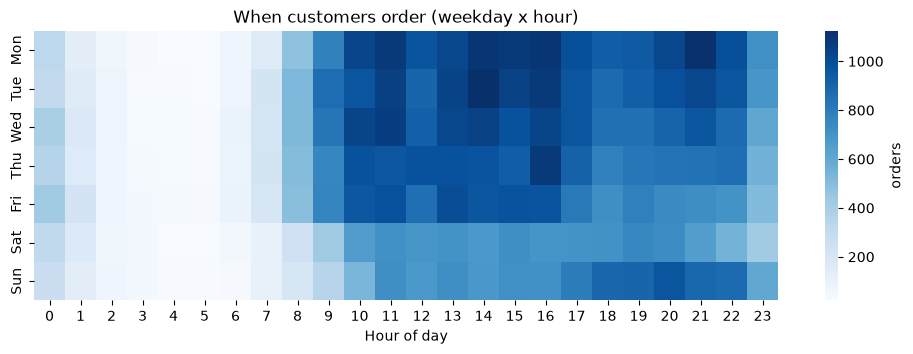

weekday
Mon    16196
Tue    15963
Wed    15552
Thu    14761
Fri    14122
Sat    10887
Sun    11960
Name: orders, dtype: int64


,weekday_num,weekday,hour,orders
62,2,Tue,14,1124
45,1,Mon,21,1118
38,1,Mon,14,1096
40,1,Mon,16,1094
64,2,Tue,16,1081


In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

timing = run_sql("07_order_timing.sql")
order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
grid = timing.pivot(index='weekday', columns='hour', values='orders').reindex(order)

plt.figure(figsize=(12, 3.5))
sns.heatmap(grid, cmap='Blues', cbar_kws={'label': 'orders'})
plt.title('When customers order (weekday x hour)')
plt.xlabel('Hour of day'); plt.ylabel('')
plt.savefig(BASE / "reports" / "figures" / "sql_order_timing.png", dpi=150, bbox_inches='tight')
plt.show()

print(timing.groupby('weekday')['orders'].sum().reindex(order))
timing.sort_values('orders', ascending=False).head(5)

**Result (query 07).** Monday is the busiest day (16,196 orders), Tuesday close behind; Saturday (10,887) and Sunday (11,960) are the quietest. Orders are near zero from 03:00 to 05:00, rise from 08:00, and stay high from 10:00 to 22:00. The busiest slots are Tuesday 14:00 (1,124) and Monday 21:00 (1,118).
The heatmap shows what daily totals hide: Sunday evening (18:00 to 22:00) is as busy as a weekday evening, while Saturday stays quiet all day.
For a webshop: send campaigns early in the week, around midday or early evening, and use Sunday evening rather than Saturday for weekend sends.

## Query 08. Cohort retention: do new customers come back?
Customers are grouped by the month of their first order (their cohort). For each cohort: the share who ordered again within 90 and 180 days.
People are counted with customer_unique_id; cancelled and unavailable orders are excluded; a second order on the same day as the first is not counted as coming back (usually a split purchase). Cohorts end in February 2018 so every cohort has a full 180 days of data (the data ends in September 2018).

In [18]:
%%writefile ../sql/08_cohort_retention.sql
-- Cohort retention: of customers who first ordered in month X, what share ordered again
-- within 90 and 180 days? Person = customer_unique_id. Cancelled/unavailable orders excluded.
-- "Again" means at least 1 day after the first order (same-day orders are usually split purchases).
-- Cohorts up to Feb 2018, so each has a full 180 days before the data ends (Sep 2018).

WITH person_orders AS (
    SELECT c.customer_unique_id      AS person,
           o.order_purchase_timestamp AS ts
    FROM orders    AS o
    JOIN customers AS c ON c.customer_id = o.customer_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
),
with_first AS (
    SELECT person, ts,
           MIN(ts) OVER (PARTITION BY person) AS first_ts
    FROM person_orders
),
per_person AS (
    SELECT person,
           strftime('%Y-%m', first_ts) AS cohort,
           MAX(CASE WHEN julianday(ts) - julianday(first_ts) BETWEEN 1 AND 90  THEN 1 ELSE 0 END) AS back_90,
           MAX(CASE WHEN julianday(ts) - julianday(first_ts) BETWEEN 1 AND 180 THEN 1 ELSE 0 END) AS back_180
    FROM with_first
    GROUP BY person, cohort
)
SELECT cohort,
       COUNT(*)                        AS new_customers,
       ROUND(100.0 * AVG(back_90), 2)  AS back_within_90d_pct,
       ROUND(100.0 * AVG(back_180), 2) AS back_within_180d_pct
FROM per_person
WHERE cohort BETWEEN '2017-01' AND '2018-02'
GROUP BY cohort
ORDER BY cohort;

Writing ../sql/08_cohort_retention.sql


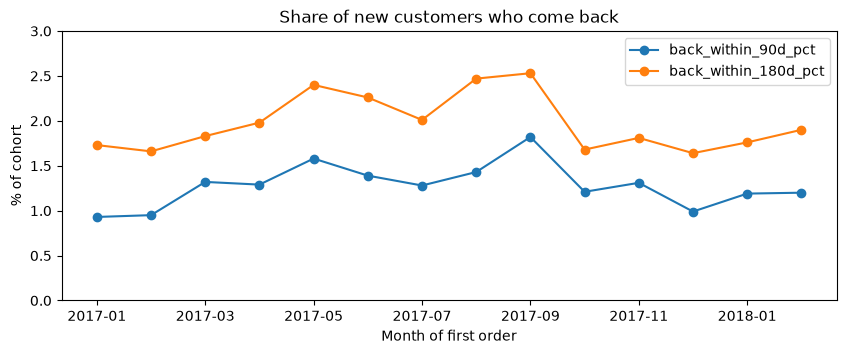

,cohort,new_customers,back_within_90d_pct,back_within_180d_pct
0,2017-01,752,0.93,1.73
1,2017-02,1690,0.95,1.66
2,2017-03,2571,1.32,1.83
3,2017-04,2325,1.29,1.98
4,2017-05,3541,1.58,2.40
5,2017-06,3102,1.39,2.26
6,2017-07,3822,1.28,2.01
7,2017-08,4130,1.43,2.47
8,2017-09,4075,1.82,2.53
9,2017-10,4392,1.21,1.68


In [19]:
cohorts = run_sql("08_cohort_retention.sql")

ax = cohorts.plot(x='cohort', y=['back_within_90d_pct', 'back_within_180d_pct'],
                  marker='o', figsize=(10, 3.5), title='Share of new customers who come back')
ax.set_ylabel('% of cohort'); ax.set_xlabel('Month of first order'); ax.set_ylim(0, 3)
plt.savefig(BASE / "reports" / "figures" / "sql_cohort_retention.png", dpi=150, bbox_inches='tight')
plt.show()
cohorts

**Result (query 08).** Retention is very low: of each monthly cohort, 0.9% to 1.8% order again within 90 days and 1.6% to 2.5% within 180 days. The best cohort is September 2017 (1.82% and 2.53%).
From October 2017, as cohorts grew much larger, 180-day retention fell to 1.6% to 1.9%: faster growth seems to have brought less loyal customers (a plausible reading, not proven).
The Black Friday cohort (November 2017, the largest with 7,190 new customers) came back no more often than others (1.31% and 1.81%): the campaign brought volume, not loyalty.
For a webshop: retention needs its own programme (personal follow-ups for high-value new customers, cross-sell), as planned in stage 2.

## Query 09. Cross-sell: what do repeat buyers buy next?
For each person's first and second order (at least 1 day apart), the category of each (first item of the order). A self-join places each order next to the person's following order.
Answers: do customers come back for the same category or a different one, and which categories lead to which? Used for cross-sell emails and bundles.

In [20]:
%%writefile ../sql/09_cross_sell.sql
-- Cross-sell: what category do repeat buyers choose for their second order?
-- Person = customer_unique_id; category = the order's first item; cancelled/unavailable excluded.
-- Second order must be at least 1 day after the first (same-day orders are usually split purchases).
-- Self-join: the ordered list of each person's orders is joined to itself, order n to order n + 1.

WITH order_category AS (
    SELECT oi.order_id,
           COALESCE(t.product_category_name_english, 'unknown') AS category
    FROM order_items AS oi
    LEFT JOIN products AS p ON p.product_id = oi.product_id
    LEFT JOIN category_translation AS t ON t.product_category_name = p.product_category_name
    WHERE oi.order_item_id = 1
),
person_orders AS (
    SELECT c.customer_unique_id       AS person,
           o.order_purchase_timestamp AS ts,
           oc.category
    FROM orders         AS o
    JOIN customers      AS c  ON c.customer_id = o.customer_id
    JOIN order_category AS oc ON oc.order_id   = o.order_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
),
sequenced AS (
    SELECT person, ts, category,
           ROW_NUMBER() OVER (PARTITION BY person ORDER BY ts) AS n
    FROM person_orders
),
first_second AS (
    SELECT a.category AS first_category,
           b.category AS next_category,
           julianday(b.ts) - julianday(a.ts) AS days
    FROM sequenced AS a
    JOIN sequenced AS b ON b.person = a.person AND b.n = a.n + 1
    WHERE a.n = 1
      AND julianday(b.ts) - julianday(a.ts) >= 1
)
SELECT first_category,
       next_category,
       COUNT(*)          AS buyers,
       ROUND(AVG(days))  AS avg_days_between,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY first_category), 1)
                         AS share_of_category_repeaters_pct
FROM first_second
GROUP BY first_category, next_category
ORDER BY buyers DESC;

Writing ../sql/09_cross_sell.sql


In [21]:
pairs = run_sql("09_cross_sell.sql")

total = pairs['buyers'].sum()
same = pairs.loc[pairs['first_category'] == pairs['next_category'], 'buyers'].sum()
print("Repeat buyers:", total)
print("Next order in the SAME category:", round(same / total * 100, 1), "%")
print("Average days to second order:", round((pairs['buyers'] * pairs['avg_days_between']).sum() / total))

pairs[pairs['first_category'] != pairs['next_category']].head(10)

Repeat buyers: 1991
Next order in the SAME category: 38.2 %
Average days to second order: 117


,first_category,next_category,buyers,avg_days_between,share_of_category_repeaters_pct
13,bed_bath_table,furniture_decor,21,75.0,8.9
14,furniture_decor,bed_bath_table,18,169.0,11.0
16,housewares,bed_bath_table,16,107.0,13.7
17,bed_bath_table,housewares,14,115.0,5.9
18,furniture_decor,housewares,13,77.0,7.9
20,furniture_decor,health_beauty,11,261.0,6.7
21,bed_bath_table,baby,10,134.0,4.2
22,bed_bath_table,computers_accessories,10,96.0,4.2
23,garden_tools,furniture_decor,10,107.0,11.9
24,sports_leisure,watches_gifts,10,181.0,5.1


**Result (query 09).** 1,991 people placed a second order at least a day after their first, on average about 117 days later. 61.8% switched to a different category; 38.2% stayed in the same one. Repeat customers are cross-sell customers, consistent with stage 2.
The clearest pattern is a home cluster: bed, bath & table, furniture & decor and housewares lead to each other. The most common move, bed, bath & table to furniture & decor (21 people), happens after about 75 days, faster than average.
Caveat: each pair has only 10 to 21 people, so these are directions to test, not proven rules.
For a webshop: about two to three months after a bed, bath & table purchase, send a cross-sell email with decor and housewares.

## Query 10. Nordic reviews: what do Danish, Swedish and Norwegian customers write about?
The 30,000 ScandiSent Trustpilot reviews are loaded into the database (table nordic_reviews). Topic words per language are written in the query as a VALUES list and joined to the reviews with LIKE (text search). Each review counts once per topic.

In [22]:
topics = run_sql("10_nordic_review_topics.sql")
topics.pivot_table(index='topic', columns=['sentiment', 'market'], values='pct_of_reviews')

sentiment      negative               positive              
market          Denmark Norway Sweden  Denmark Norway Sweden
topic                                                       
Delivery           21.1   27.6   24.8     28.6   40.9   39.9
Money / refund     30.7   13.3   18.2      3.4    1.4    1.9
Price               9.4    7.1    6.6     11.4    9.7   10.4
Quality             5.1    4.2    2.1      8.0    6.8    3.8
Reply              29.7   23.5   27.7      5.1    3.7    3.7
Service            25.6   23.8   21.8     32.8   20.5   16.4
Speed               6.8    5.6    4.7     36.4   42.7   49.5

**Result (query 10).** Tested against the stage 4 pandas results: identical except one cell (Sweden, service, negative: 21.8% vs 21.9%; SQLite's LOWER only lowercases plain English letters, so words in capitals with Swedish letters such as KUNDTJÄNST are missed).

The same pattern holds in Denmark, Norway and Sweden:
- Speed is the main praise topic: mentioned in 36% to 50% of positive reviews but only 5% to 7% of negative ones.
- Missing replies (24% to 30% of negative reviews vs 4% to 5% of positive) and money or refunds (13% to 31% vs 1% to 3%) are complaint topics.
- Delivery and service appear on both sides: done well they are praised, done badly they are criticised.
- Price (7% to 11%) and quality (2% to 8%) are mentioned far less: reviews are mostly about the experience, not the product or price.

Countries are not compared directly: Danish reviews are about twice as long, so they mention more topics overall. The reliable comparison is negative vs positive within each country.
For a Nordic webshop: reply fast, make refunds quick and visible, and promise delivery times you can beat.